# openpilot supercombo on Bench2Drive: change the image, see the plan

This is the Bench2Drive twin of [the KITScenes image-tweak notebook](openpilot_drv_supcombo_kitscenes_image_tweak.ipynb) and [the comma2k19 one](openpilot_drv_supcombo_comma2k19_image_tweak.ipynb). It runs no sweeps. You edit one config and see what it does:

1. **Five turns, as stock plans them.** For each turn:
    - the four images the model was given (each view's two frames);
    - the GT and the plan drawn on the keyframe;
    - the warps that cut each view out of the camera image, and the road's homography into each view;
    - the camera, and the rows openpilot expects the horizon on.
2. **One turn, `FOCUS`: how the height and speeds are measured.** Both the real values and the values the model reads.
3. **`CONFIG`, a change to what the model is fed, on that turn.** Edit it and re-run the cell. The model plans again, and the new plan is drawn beside stock's (or beside any other config). A `noise` row shows how much a half-pixel shift alone changes each number. A config can change:
    - the image: its geometry, sampling and tone;
    - the source: a cut of the frame to a narrower field of view, such as comma's 65°;
    - the intent: whether the route's turn is sent as openpilot's desire.
4. **The same config on all five turns**, scored against stock (or any other config) on ADE, alignment with the GT and the speed profile. Each change is judged against a noise floor.
5. **Several configs side by side on all five turns**, for example stock, with intent, and with a lane-change desire as its control.

**What the data is.** Bench2Drive is closed loop in paddock: a run drives CARLA, and nothing records open-loop plans. This notebook reads the Bench2Drive base set instead, CARLA drives recorded by Bench2Drive's expert at 10 Hz, each frame with an annotation. A sample is a keyframe, the 4.8 s of frames before it and the 10 s of the drive after it:
- **The observations** are built from the annotations the way paddock's CARLA agent builds them: the front camera's frame, the car's pose y-flipped into paddock's frame and set on the ground, the speed and acceleration in the canbus, and the camera's calibration with the optical axes. Every command is STRAIGHT. The agent imports carla, so the lib restates its conventions rather than importing them.
- **The camera** is the dataset's front camera, 1600 × 900 at 70° across, 1.6 m up and level. paddock's own closed-loop rig mounts its front camera elsewhere (1.5 m up, 800 × 450), so these frames are not the ones a paddock run would show the model.
- **The GT** is where the point under the camera goes over the next 10 s, in the camera's frame at the keyframe: openpilot plans from its camera, and the camera is mounted square, so the plan and the GT share one frame.
- **The scores** are paddock's open-loop ones (`paddock.metrics.openloop.decompose`), the definitions comma2k19 and KITScenes score with.

**What is different from KITScenes and comma2k19.**
- The camera is rendered, not real. It is wider than comma's (70° against 65.2°) and higher (1.6 m against 1.22 m), and level, so openpilot's calibration is 0° roll, pitch and yaw.
- The frames come at 10 Hz, half openpilot's rate: every frame is two model ticks, and img's older frame is 2 frames back.
- There is no recorded run, so stock is run here and nothing holds it to an earlier result. The checks hold it to the stock adapter instead.
- The window is 4.8 s, inside openpilot's 5 s desire queue, so a desire sent at any lead is still queued at the keyframe.

On every view the model is shown, a solid white line marks the row openpilot expects the horizon on: row 47.6 of img's 256, row 151.8 of big_img's.

**How it runs**
- **The code** is in [`openpilot_drv_supcombo_bench2drive_image_tweak_lib.py`](openpilot_drv_supcombo_bench2drive_image_tweak_lib.py), next to this notebook. Restart the kernel after editing it.
- **Paddock never imports a model, and neither does this notebook.**
    - The model runs in [`openpilot_drv_supcombo_image_node.py`](openpilot_drv_supcombo_image_node.py), the node the KITScenes and comma2k19 notebooks use. It is the stock adapter; only the way it makes the warps and tensors is changed.
    - The node runs in openpilot's own interpreter, the same way `paddock run` launches a model. The notebook sends it matrices and lookup tables over localhost.
    - The checks before part 3 show that, with no config, the node is the stock adapter bit for bit.
- **It needs `[datasets.bench2drive]`** in `paddock.toml`, its `path` the directory that holds the clips (`<clip>/anno`, `<clip>/camera/rgb_front`).
- **It runs on CPU by default.** The nodes start the first time they are needed, one per turn.
- **Every result is cached** under `{runs}/bench2drive/_analysis/openpilot/image_tweak/`. The cache key is the matrices sent, the sample, the cut it came from, the desire, the device and a hash of the code. Running the same config again costs nothing.
- **The frames** are the dataset's JPEGs, read in place. A cut (`fov_deg`) is staged once per turn under the cache, as raw arrays.

**The committed outputs are stock.** `CONFIG` leaves the image unchanged and part 5 has the one arm, stock, so parts 3–5 show stock against itself. They were made on CPU by `.venv/bin/jupyter execute --inplace`.

In [ ]:
import sys

import pandas as pd

from paddock.config import REPO_ROOT

sys.path.insert(0, str(REPO_ROOT / "tools/models/openpilot/analysis"))  # the lib, beside this notebook
import openpilot_drv_supcombo_bench2drive_image_tweak_lib as T

pd.set_option("display.max_columns", 50)  # part 4's per-turn table has 31 columns

## Parameters

- **`SCENES`**: the five turns. Wherever a cell takes a key, the key can be:
    - a sample id, such as `"bench2drive/ConstructionObstacle_Town05_Route68_Weather8/111"` (the clip, then the keyframe);
    - a label such as `"ConstructionObstacle/111"` (the clip's scenario, then the keyframe);
    - a clip or its unique prefix, then the keyframe, such as `"AccidentTwoWays_Town12/240"`.

    Any keyframe of any clip works, from frame 48 (4.8 s of history) to the clip's second-last frame.
- **`FOCUS`**: the turn that parts 2 and 3 work on.
- **`DEVICE`**: `"cpu"`, or `"cuda"` if a GPU is free. **`NODES`** is the number of model processes; **`THREADS`** is the threads each one uses.
- **`HEIGHT`**: the camera's real height. It is used to draw the road and by the knobs that move the camera. One of:
    - `"rig"`: the annotation's `cam2ego`, 1.6 m;
    - a number in metres.
- **`OVERRIDES`**: tag parameters for the turn classes, for example `{"curv_under": 0.6}`.
- **`RECOMPUTE`**: ignore the cached results.
- **`OVERLAY`**: where the GT and the plans are drawn.
    - `"img"`: the keyframe of the narrow view.
    - Add `"big_img"` for the wide view, or `"camera"` for the photo.

In [ ]:
SCENES = [
    "bench2drive/VehicleTurningRoute_Town15_Route443_Weather1/133",
    "bench2drive/ConstructionObstacle_Town05_Route68_Weather8/111",
    "bench2drive/AccidentTwoWays_Town12_Route1444_Weather0/240",
    "bench2drive/Accident_Town03_Route156_Weather0/132",
    "bench2drive/AccidentTwoWays_Town12_Route1444_Weather0/274",
]
FOCUS = "ConstructionObstacle/50"
DEVICE = "cpu"
NODES, THREADS = 5, 8
HEIGHT = "rig"
OVERRIDES = {}
RECOMPUTE = False
OVERLAY = ("img",)  # add "big_img" or "camera" to see more of the path

lab = T.Lab(
    SCENES,
    device=DEVICE,
    nodes=NODES,
    threads=THREADS,
    height=HEIGHT,
    overrides=OVERRIDES,
    recompute=RECOMPUTE,
)

5 turns; code ecceef83e4 (openpilot 555f48c5d); model on cpu, 5 node(s); cache {runs}/bench2drive/_analysis/openpilot/image_tweak


## 1 Five turns, as stock plans them

"Stock" here is stock run by the node, on this machine; check 1 below shows the node with no config is the stock adapter bit for bit. Nothing recorded these turns open loop, so there is no earlier run to hold it to.

The turns were picked from the ten clips on disk for a heading change the car drives through: it keeps moving at 2.5 m/s or more over the first 3 s, and its heading 7–10 s on still points the way it turned. That rules out the keyframes where the car stops, and the swerves that come back to where they started. The five are of two kinds:
- **Three slow right turns**, where the car pulls away from a crawl: its mean speed over the 4.8 s window is 0.7–1.1 m/s, and within 3 s of the keyframe it reaches 7–11 m/s.
- **Two fast lefts that are not road curves.** At 10 m/s, the car is squaring back up to the road after going round the accident: at the keyframe it points 23° (Accident/132) and 32° (AccidentTwoWays/274) right of the road, and the expert swings it back at about 50°/s, within a second. The GT then runs along the road, already about 15° left of the car's heading at its first step.

They cover three of the turn classes:

| turn | route | speed | GT's turn over 3 s | stock's | stock |
|---|---|---|---|---|---|
| VehicleTurningRoute/133 | right | 3.2 m/s | 23° | 48° | turns twice as far by 3 s |
| ConstructionObstacle/111 | right | 3.2 m/s | 49° | 20° | turns too little by the clock, but on the GT's path (0.17 m off it) |
| AccidentTwoWays/240 | right | 4.3 m/s | 34° | 35° | matched |
| Accident/132 | left, back onto the road | 10.0 m/s | 8° | 12° | turns too far by heading, yet 4.1 m right of the GT's path: it turns later |
| AccidentTwoWays/274 | left, back onto the road | 10.4 m/s | 10° | 12° | matched by heading, yet 5.0 m right of the GT's path; the worst ADE |

None of the five goes unplanned, and stock turns toward the route on all of them.

The columns, here and in every table below:
- **`mode`**: the open-loop notebook's turn class. The first match wins:
    - `not_planned`: the plan's heading changes by less than 15° over its 10 s;
    - `wrong_way`: it turns 15° or more away from the route;
    - otherwise the class compares the plan's turn with the GT's over 3 s: `understeer` under 0.7 of it, `oversteer` 1.3 or more, `matched` in between.
- **`ade`**: the benchmark's score, the mean distance from the GT over 3 s (m).
- **`ade_long`**: the same over the GT's whole length, up to 10 s.
- **`lat`**: the benchmark's mean lateral error over 3 s (m), between the plan and the GT at the same time.
- **`path_err`**: the mean distance from the plan's waypoints over 3 s to the GT's path, wherever along it they fall (m). It ignores timing: a plan on the GT's line scores 0, however slowly it drives it.
- **`dpsi`, `gt_dpsi`**: the plan's and the GT's heading change over 3 s (deg). Positive is toward the route.
- **`turn_frac`**: the plan's share of the GT's turn, over the GT's whole length.
- **`speed_rmse`**: the RMS difference between the plan's and the GT's speeds over 3 s, per 0.5 s step (m/s).
- **`v0_ratio`**: the speed of the plan's first step over the GT's.
- **`head_ratio`**: the pose head's speed over the car's, the annotation's `speed`.
- **`plan_v0`**: the plan's own start speed (m/s).
- **`cam_h`**: the camera height the model reads (m). The real one is the rig's, 1.6 m. Part 2 says how each is measured.
- **`p_turn`** (parts 3–5): the probability the model's desire-state head gives the route's turn (turn left or turn right) at the keyframe. It shows whether the model thinks it is turning, whether or not it was sent the intent.

In [ ]:
lab.stock_table().round(3)

,route,v,mode,ade,ade_long,lat,path_err,dpsi,gt_dpsi,turn_frac,speed_rmse,v0_ratio,head_ratio,plan_v0,cam_h
key,,,,,,,,,,,,,,,
VehicleTurningRoute/133,"right, -23 deg",3.244,oversteer,2.805,9.384,0.839,0.959,47.538,23.096,2.473,1.761,0.670,0.707,2.346,1.407
ConstructionObstacle/111,"right, -31 deg",3.237,understeer,5.402,16.824,3.685,0.171,19.826,49.001,1.064,4.589,0.610,0.650,2.377,1.422
AccidentTwoWays/240,"right, -20 deg",4.287,matched,3.428,12.106,1.312,0.590,35.155,34.298,2.018,2.823,0.751,0.739,3.363,1.388
Accident/132,"left, +21 deg",10.002,oversteer,4.794,9.234,2.791,4.084,12.294,8.471,0.930,2.007,1.149,0.370,9.664,1.250
AccidentTwoWays/274,"left, +11 deg",10.393,matched,5.943,10.073,5.875,4.988,12.082,10.186,1.352,1.097,0.790,0.738,7.809,1.271


Each figure shows one turn:
- **Top row:**
    - the camera's keyframe, with the outlines of img (yellow) and big_img (cyan) and the road at its real height;
    - the paths seen from above;
    - the speed and the heading at each 0.5 s step.
- **Bottom row:** the four images the model was given. Each view has two frames: the frame 0.2 s before the keyframe, then the keyframe. The GT and the plan are drawn on the keyframe of each `OVERLAY` view, placed where the real camera sees them.

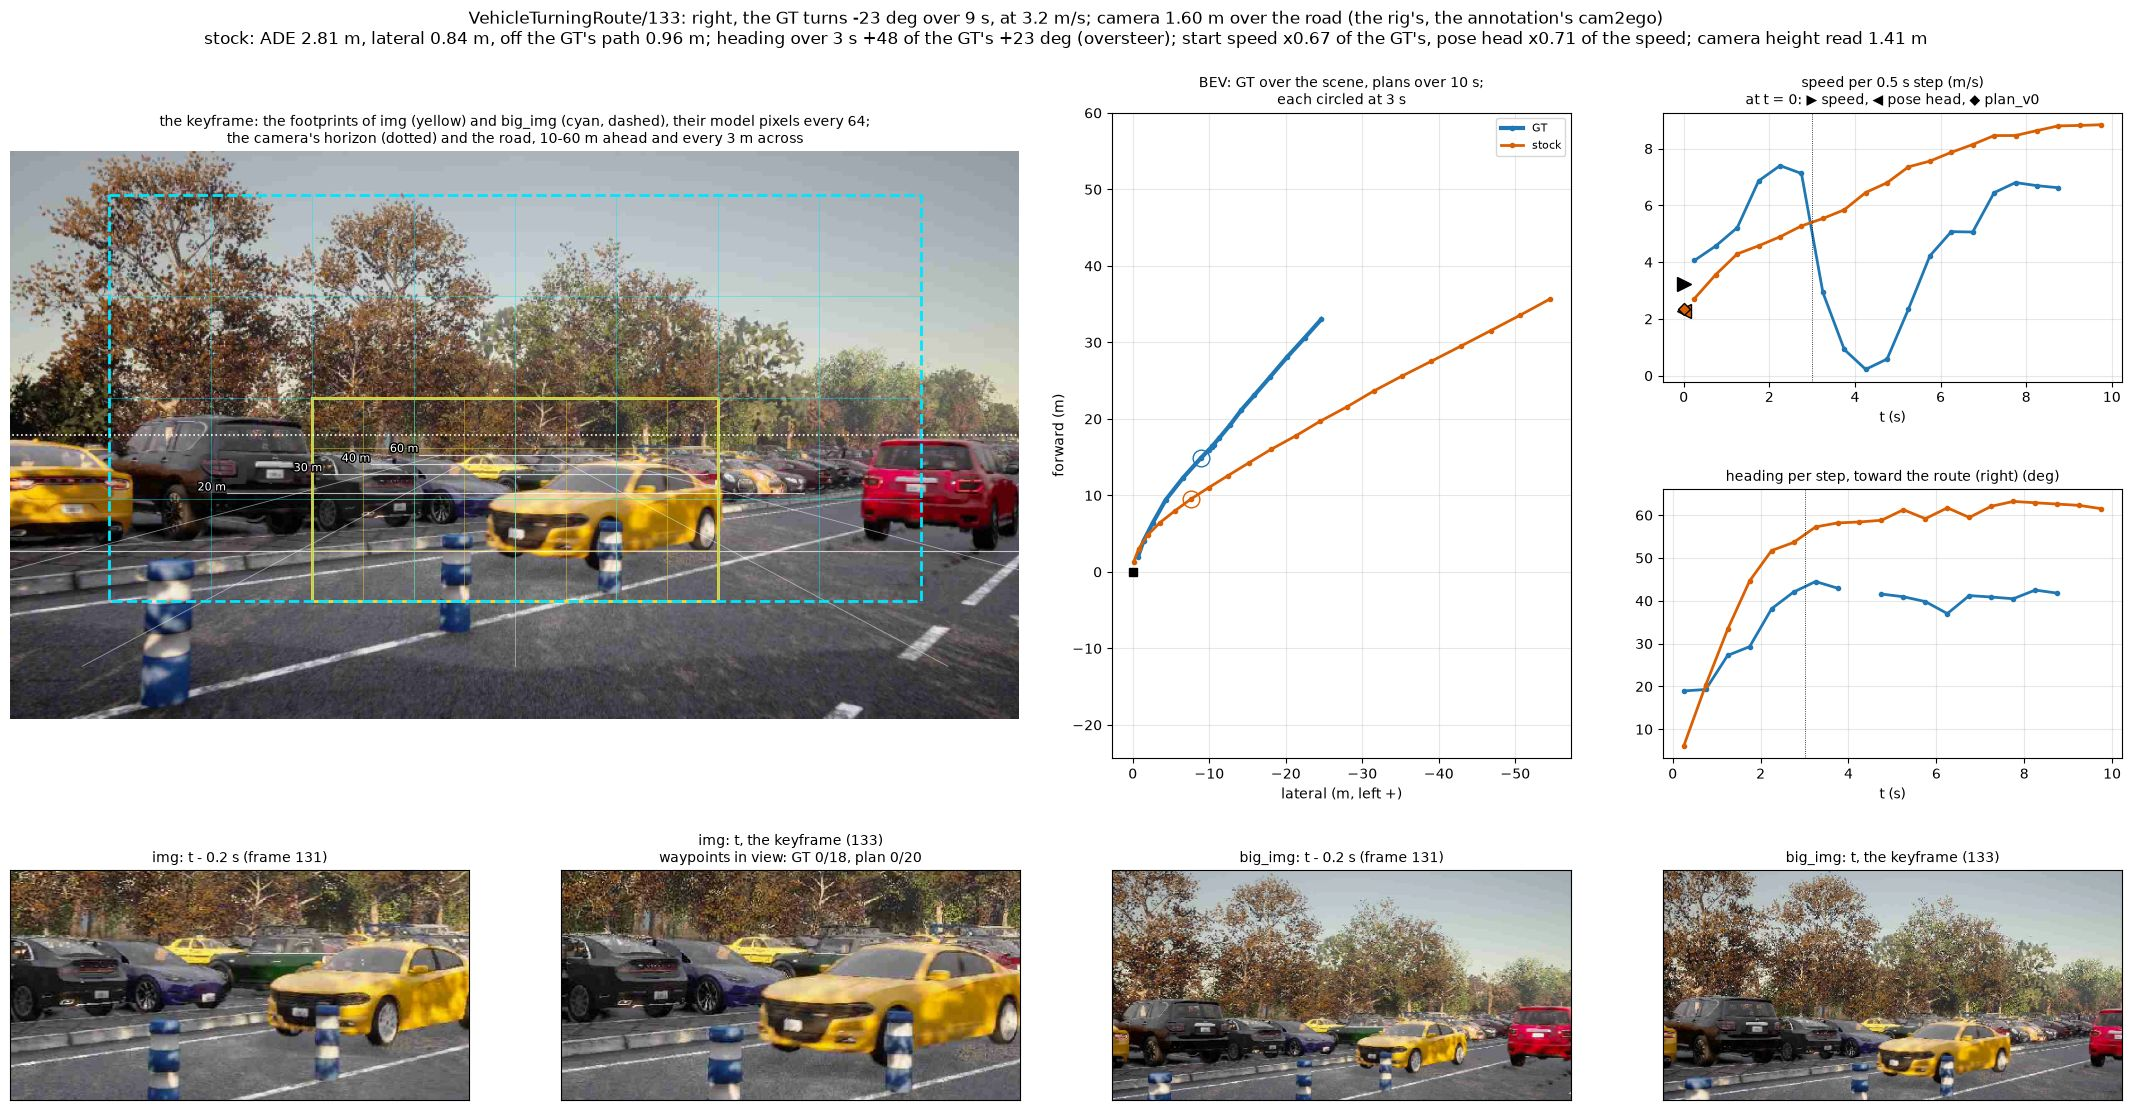

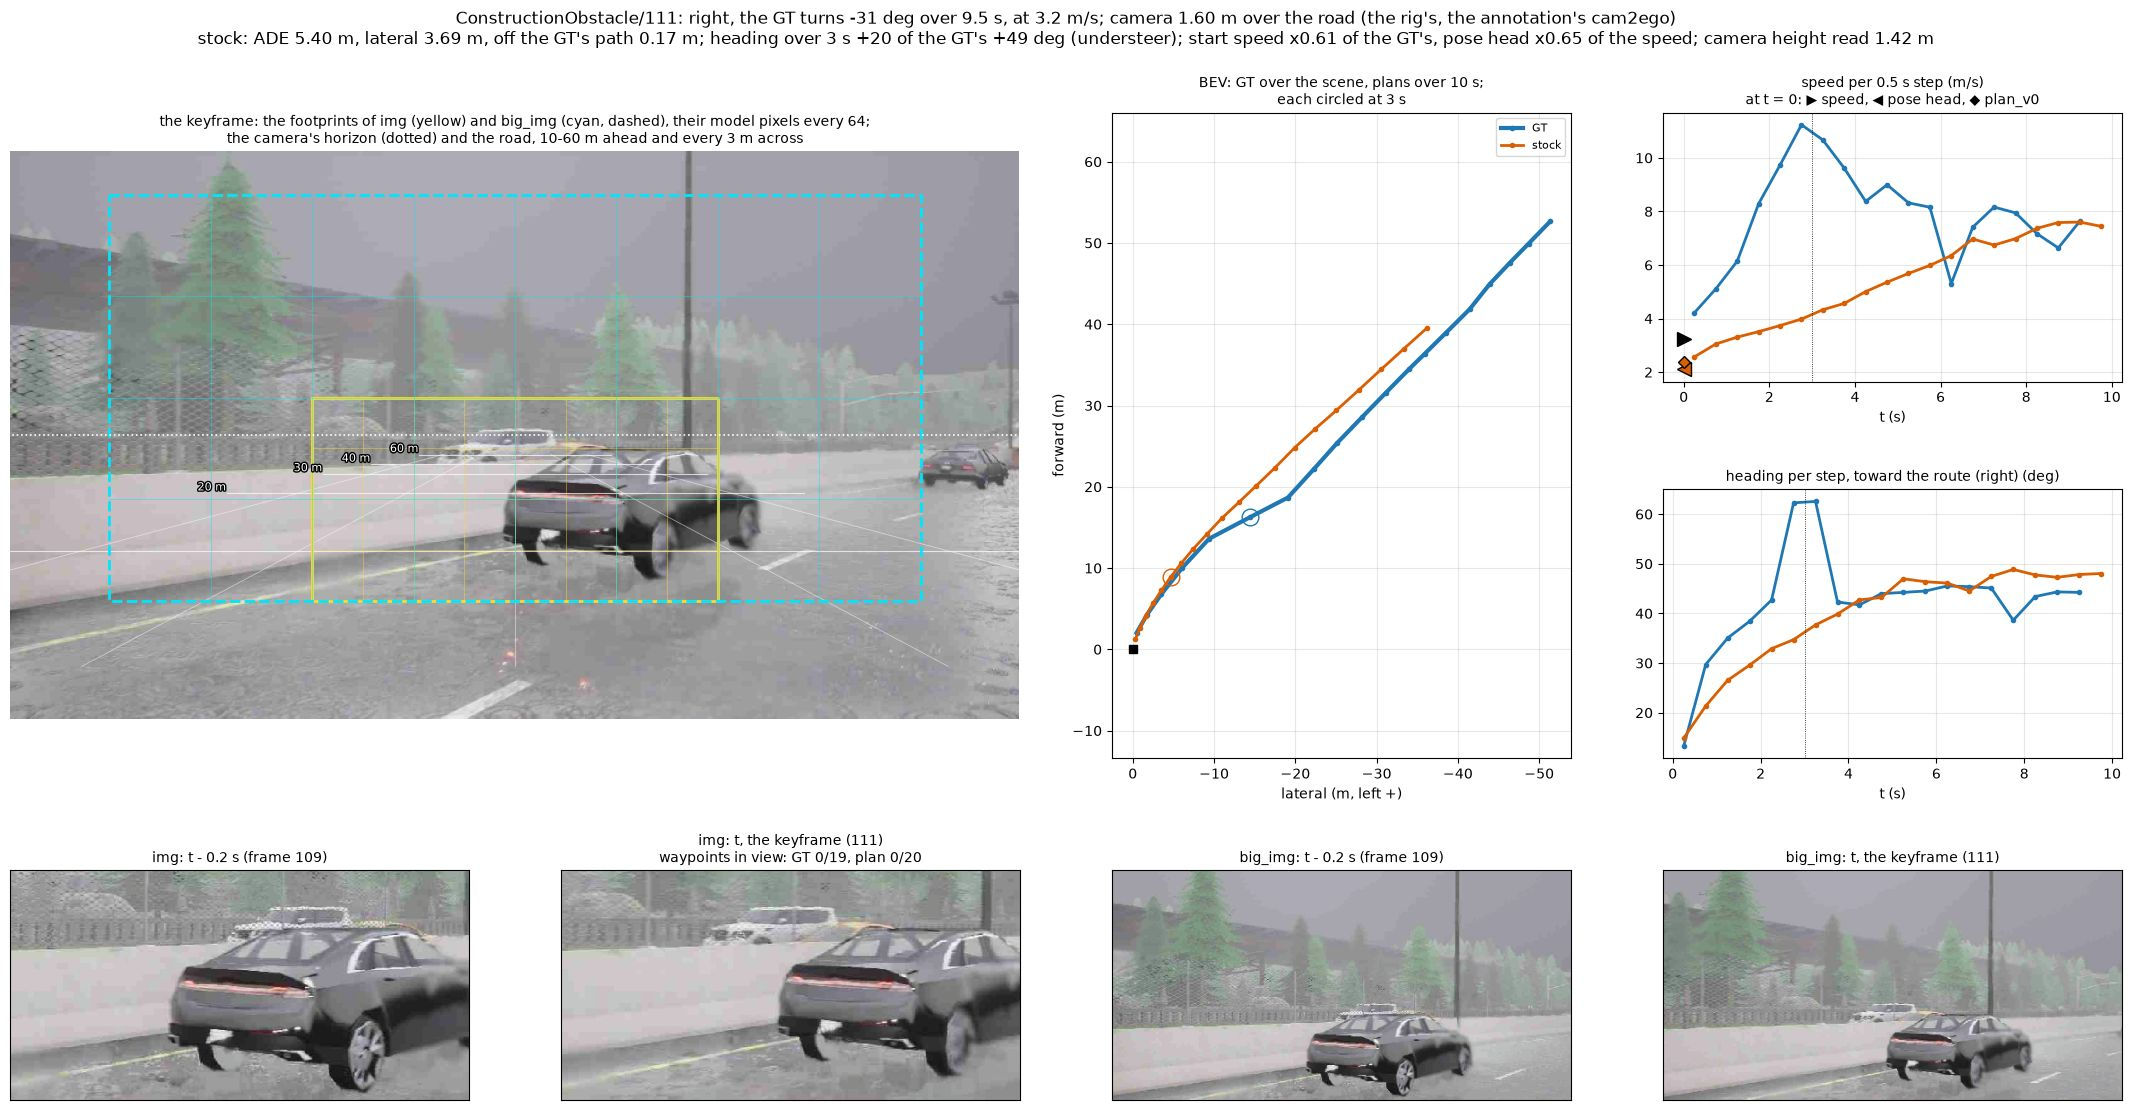

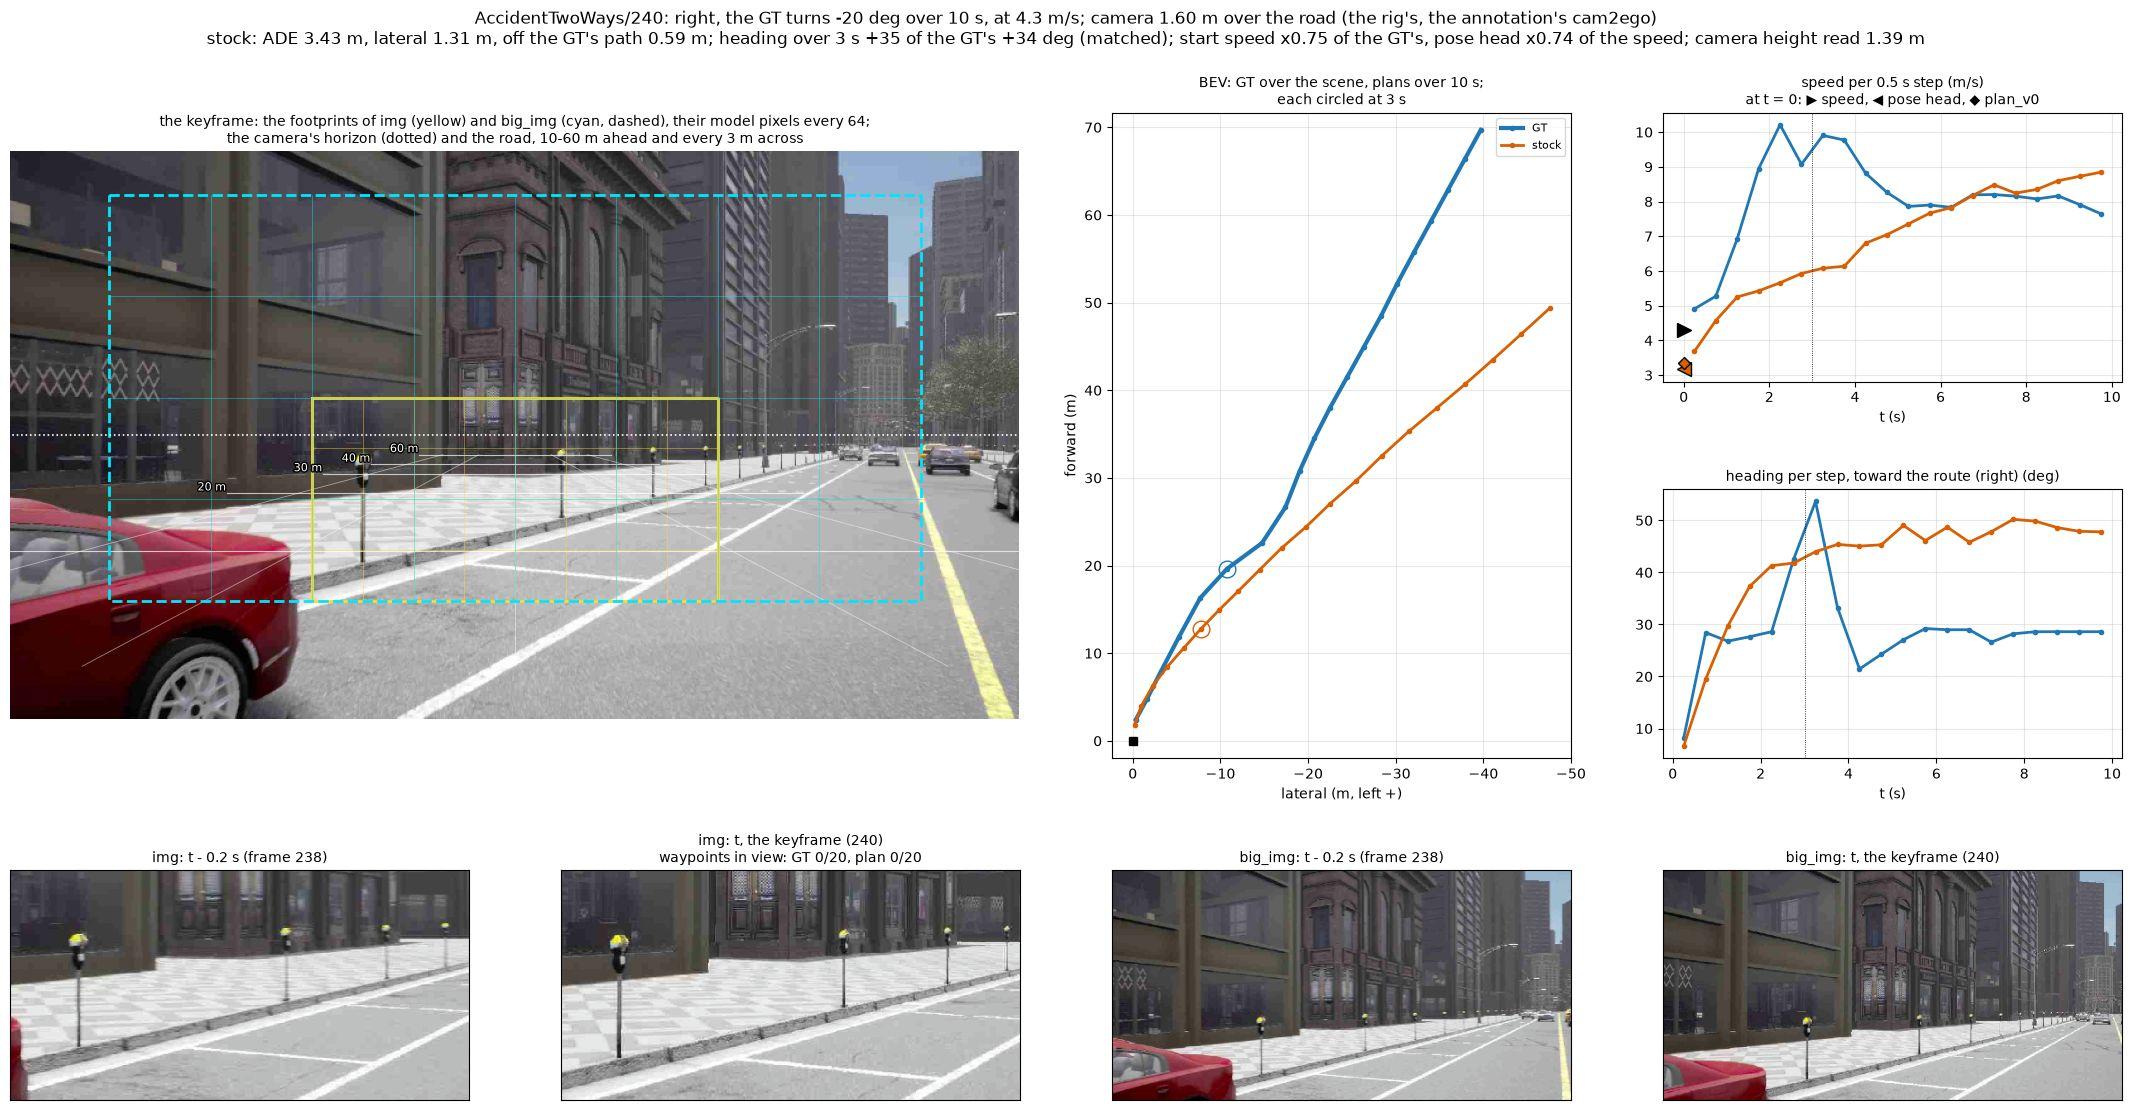

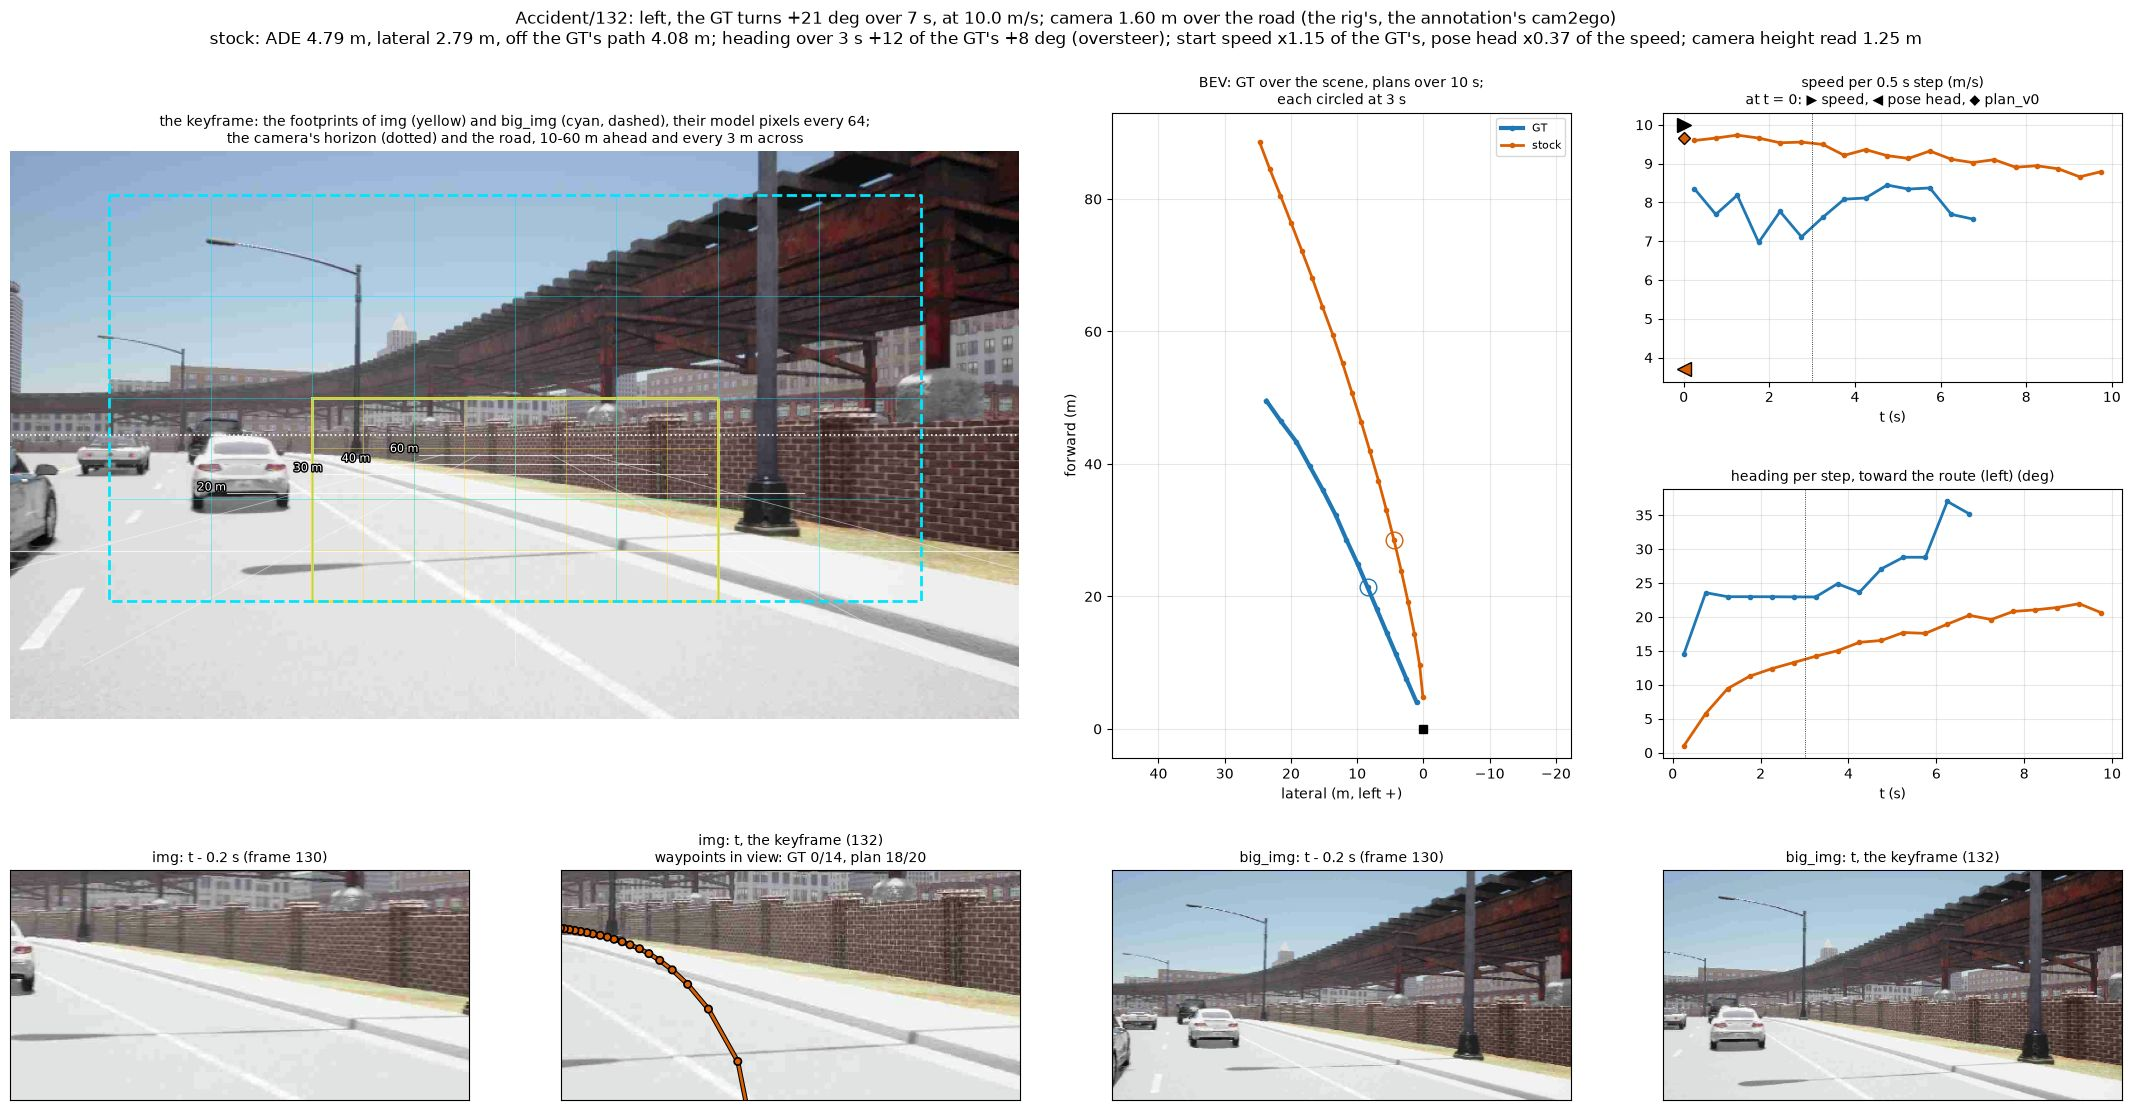

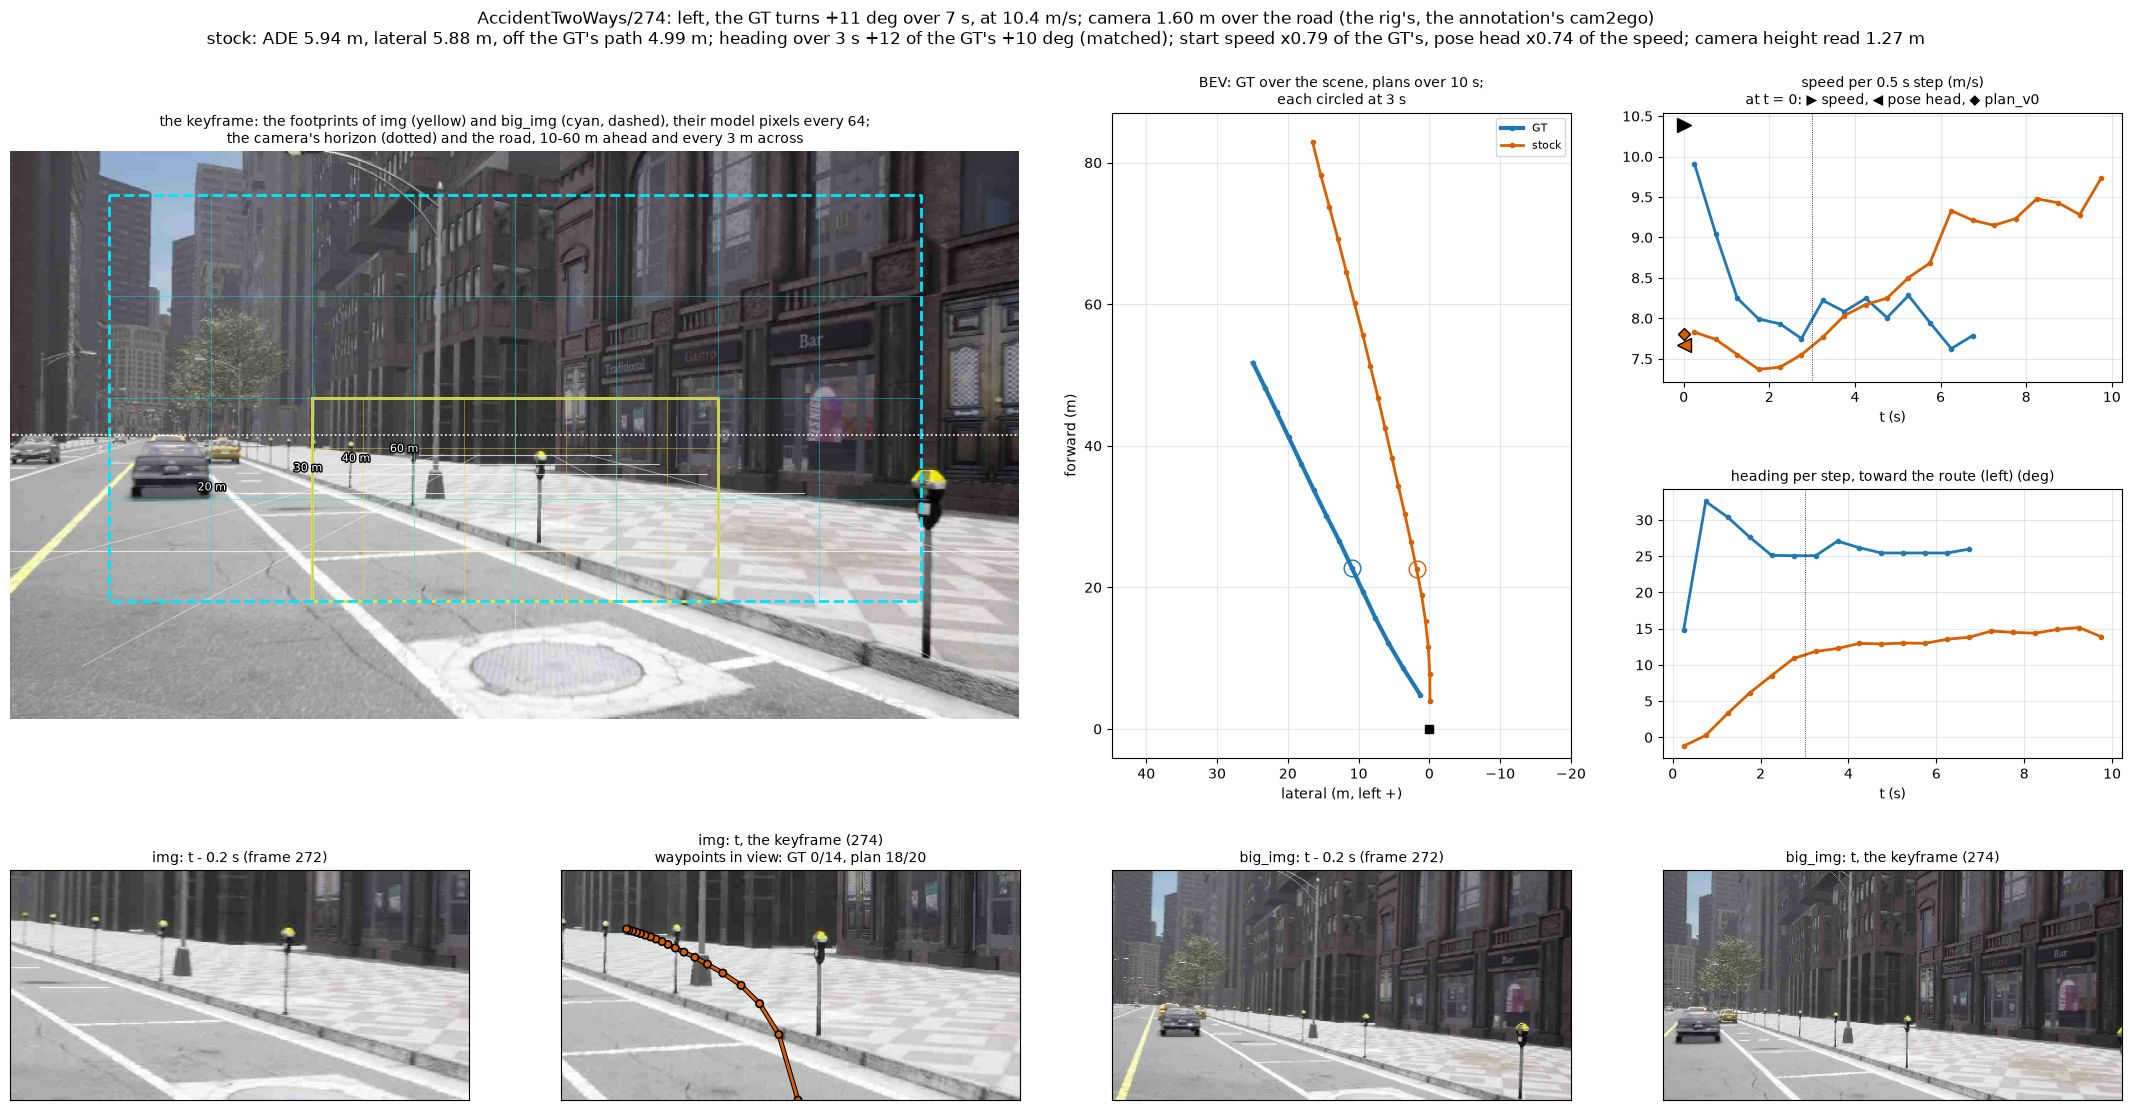

In [ ]:
for key in lab.keys:
    lab.show_stock(key, overlay=OVERLAY)

**How much of the path img sees.** Each view's title counts the waypoints inside it. img spans ±15.7° across and about 3° above to 13° below the camera's axis. It holds none of the GT's waypoints on any of the five turns:
- **The three slow rights** turn out of img's side within a few metres. big_img, ±29.4° across, holds at most 3 of their 18–20.
- **The two lefts** run along the road, 15–26° left of the car's heading, outside img's side from the first step. big_img holds 12 and 13 of their 14. Stock's plans stay nearer straight ahead: 18 of their 20 waypoints are inside img.

To draw the path where it can be seen, set `OVERLAY = ("img", "big_img", "camera")`. The photo shows the camera's whole 70° across.

### The warp and the homographies

The model never sees the camera's image directly. Each view is cut out of it by a 3 × 3 homography, one per view for each camera:

`W[view] = camera_from_calib @ calib_from_model[view]`

- **`calib_from_model[view]`** is openpilot's own and is the same for every car. It maps a model pixel to a ray in the calibrated frame (x forward, y right, z down).
- **`camera_from_calib`** belongs to the camera: its intrinsics K, times the mount's rotation (the roll, pitch and yaw openpilot reads from `camera2ego`). The CARLA camera is level, so here the rotation is the identity and every turn has the same W: img is the camera's centre at 1.26 camera px per model px (openpilot defines img at comma's 910 px focal length; this camera's is 1142.5 px), and big_img spans 2.51.

So W contains a rotation and a focal change, but no camera height. The height enters through the road's homography into each view:

`inv(W[view]) @ G`, where `G = K @ [r1 r2 t]`

G maps a road point (x, y, 1) to a camera pixel, for a camera h metres above the road.

The cell below shows three things:
1. the matrices for `FOCUS`;
2. the road grid drawn through each view's homography, on all five turns;
3. a table of each turn's camera.

Part 3's image changes are applied between the two factors of W:

`camera_from_calib @ calib @ calib_from_model[view]`

In [ ]:
lab.show_warps(FOCUS)

KeyError: "'ConstructionObstacle/20': a keyframe of ConstructionObstacle_Town05_Route68_Weather8 is 48 to 205"

### The camera, and the horizon openpilot expects

On KITScenes a config could feed the model either of two front cameras, cut to comma's 65°. Here there is one, the CARLA front camera every Bench2Drive drive recorded: 1600 × 900 px at a focal length of 1142.5 px, 70° × 43°, 1.6 m up and level. It is wider than comma's EON (65.2°) and sharper: img spans 1.26 of its pixels per model pixel, where on comma's camera it spans one.

`fov_deg` cuts the frame narrower, about its centre, and by default resamples the cut back to 1600 px across. `fov_deg=T.EON_FOV` cuts it to comma's 65.2°. The model is told the cut's true focal length, so its views still look at the same scene, and check 5 below confirms it for a 50° cut. Under about 59° (big_img spans ±29.4°), big_img reaches past the cut's edge.

The figure shows `FOCUS`: the keyframe with its views' footprints, then img and big_img at the keyframe. On each view:
- **solid white**: the row openpilot expects the horizon on. It is the row of the calibrated straight-ahead ray in openpilot's `calib_from_model`, 47.6 of 256 in img and 151.8 of 256 in big_img, the same for every car;
- **dashed white**: this camera's own horizon. With openpilot's warp the two coincide by construction, so here the dashed line hides under the solid one. In part 3, a `pitch_deg`, `roll_deg` or `fov_told_deg` moves it off.

The table gives the camera's frame, focal length, field of view, height, mounting angles, where its calibration comes from, and the camera pixels per model pixel in each view.

In [ ]:
lab.show_cameras(FOCUS)

## 2 How the height and speeds are measured, on one turn

`FOCUS`, ConstructionObstacle/111, is a right turn taken while pulling away, with a car close ahead that fills most of img. Its plan is on the right road but too slow:
- **The shape is right.** Stock's waypoints over 3 s are 0.17 m from the GT's path on average, the closest of the five.
- **The speed is not.** The car is at 3.2 m/s and accelerating hard: the GT's first step is 4.2 m/s, and by 2.75 s it is at 11.2 m/s. The plan starts at 2.6 m/s (`v0_ratio` 0.61) and reaches only 4.3 m/s by 3 s.
- **So it understeers by the clock, not by the road.** At 3 s the plan has got less far along the same curve: its heading has turned 20° of the GT's 49°. That is where its lateral error of 3.7 m and its ADE of 5.4 m come from.

The model reads its camera as low: 1.42 m, where the rig puts it at 1.6 m. On all five turns it reads 1.25–1.42 m: between the real 1.6 m and the 1.22 m it was trained at. Reading the camera too low and the car too slow go together, as below.

The model is told neither its height nor its speed. It reads both from the images, and two of its outputs show what it read:
- **`cam_h`**: the camera's height above the road plane, from supercombo's `road_transform` head;
- **the pose head**: the model's forward speed, from supercombo's `pose` head.

`plan_v0`, the plan's own start speed, is a separate output.

The tables below give every height and speed on this turn, with how each is measured. Unlike comma2k19, both real values are exact here: CARLA rendered the camera at the rig's 1.6 m and reports the car's speed. The figure shows how the two are linked:
- **Top row:** img's two frames, 0.2 s apart, and what changed between them. That change is all the image says about speed. Here most of it is the car ahead, which is moving too, not the road.
- **Bottom left:** the road 10–40 m ahead (green), and the image rows the model reads as those distances (red, dashed) at the height it reads. The plan is drawn twice: on the real road, and on the road the model reads.
    - **What geometry alone predicts** (argued). The model puts its camera at 1.42 m when it is 1.6 m up, so it reads every distance as 0.89 of the true one. It should therefore read the road between the frames as moving 0.89 as far, and so read 0.89× the true speed.
    - **What was measured.** The pose head reads 0.65× here, well under what geometry predicts. One turn cannot say why. Two candidates, neither tested here (argued): the car ahead, whose motion hides the road's, and the window, in which the car crawled at 0.8 m/s for most of 4.8 s, so the model's features from earlier ticks remember a car barely moving.
- **Bottom right:** the speeds. The GT's and the plan's are plotted per 0.5 s step, with the readings at t = 0.

In [ ]:
lab.show_measurements(FOCUS)

## Before part 3: does the node give the stock model's output?

Five checks, each of which raises an error if it fails:
1. **The node is the stock adapter.** With no config, the node gives the same plan, extras, warps and ticks as the untouched adapter, bit for bit. So does an identity config sent the way every config is sent, as `calib` and `post` matrices. So a change in the plan is the config's own, and the half-pixel shifts behind the `noise` row and part 4's floor measure the shift alone.
2. **The drawings show what the model was fed.** What this notebook draws as the model's input matches what the model received. This is checked on every path the node has: shift, supersampling, filter, tone tables and blanking.
3. **The frames are 0.1 s apart, as the timestamps tell the model.** On every turn, the camera point moves the speed annotated on the frame it reaches, ÷ 10, per frame, to within 5%. Only frames where the car moves at 1 m/s or more count: below that, the step is mostly pose jitter. A 5 Hz or 20 Hz clip would be 2× or 0.5× off. Paddock's Bench2Drive runs of openpilot are closed loop in CARLA, so they never planned these recorded frames: there is no recorded plan to reproduce, and the five samples are built from the dataset by this notebook alone.
4. **The tick counts agree.** The model ticks counted here are the node's own. img's older frame is found from them.
5. **A cut does not move the views.** For a 50° cut (`T.CHECK_CUT_DEG`), the warp openpilot computes from the cut's intrinsics equals the stock warp followed by the map from camera pixels to cut pixels, to within 0.01 cut px over a grid on each view. The mounting angles openpilot derives are unchanged. So a cut changes which pixels the views are sampled from, not where they look.

In [ ]:
lab.checks(FOCUS)

## 3 Change the image or the intent, on one turn

Edit `CONFIG` and run the cell. The model plans `FOCUS` again with the image changed, and the figure shows the result beside stock:
- **Top row:**
    - the keyframe, with stock's view outlines (grey) and the config's;
    - the road grid as the config shows it to the model (red), against where it really is (grey);
    - the paths seen from above.
- **Middle row:** the speed and the heading at each 0.5 s step.
- **Bottom rows:** the four images the model is given, stock's above the config's.
    - On the `OVERLAY` views, the GT and the plan are drawn.
    - Two horizons are drawn on each keyframe view: the row openpilot expects the horizon on (solid white, labelled: row 47.6 of img's 256, 151.8 of big_img's), and where the camera's own horizon lands in the view the config makes (dashed). Stock puts them together; a config that pitches, rolls or mis-tells the field of view pulls them apart.

The table under the figure gives part 1's metrics for stock, for the config, and the change between them. Its last row, **`noise`**, is the largest change that any of eight half-pixel shifts (`T.SHIFTS`) makes on this turn, with every turn class they give.
- The shifts move the geometry by almost nothing, so a change within `noise` is not the config's doing.
- They take eight runs the first time on each turn, cached after that. `lab.tweak(..., noise=False)` skips them.

**How to use it**
- Every value in `CONFIG` below leaves the image unchanged, and the knobs combine freely.
- Set **`RUN_MODEL = False`** to draw only what the model would be shown, in a second or two, without running the model.
- To run another turn, use `lab.tweak(key, CONFIG)` with any key.
- **`AGAINST`** sets the baseline the config is drawn and scored beside: `None` is stock, or give another config. For example, to see what intent does on a 50° cut, set `CONFIG = dict(fov_deg=50, desire="turn")` and `AGAINST = dict(fov_deg=50)`. The `noise` row then shifts the baseline, not stock.

| knob | what the model is shown | what it should do to the plan |
|---|---|---|
| `height_scale` s | the road as seen from a camera at h / s | every distance and width s× larger, so faster |
| `zoom` k | the image magnified k×, like a longer lens | distances ×1/k with widths unchanged, so slower when k > 1; a smaller field of view |
| `hstretch` g | the image stretched g× sideways | lateral offsets and lane widths ×g; curves look tighter |
| `yaw_deg` ψ | the view turned ψ left | the plan's heading turns ψ right |
| `turn_yaw_deg` | the view turned toward the route's side; negative turns it away | turned toward: the plan turns away from the route; turned away: the plan turns toward it |
| `pitch_deg` | the view tilted up, so the road sits lower | the road reads nearer, so slower |
| `roll_deg` | the view rolled, so the right side looks lower | the plan drifts sideways |
| `ahead_m`, `left_m` | the camera moved over the road, at the same height | the plan starts where that camera would stand |
| `dx_px`, `dy_px` | the sampling grid moved right and down, in model pixels | nothing beyond noise; half a pixel is the noise floor |
| `views` | which views the geometry applies to: `"both"`, `"img"` or `"big_img"` | |
| `supersample` n, `ss_views` | each model pixel the mean of n × n camera samples, in `ss_views` | big_img spans about 2.5 camera pixels per model pixel here, and img 1.26: big_img has a little to average, img almost nothing |
| `sharpen` α | an unsharp mask, δ + α(δ − blur) over 3 × 3; −1 is the blur itself | |
| `gamma`, `contrast`, `brightness`, `saturation` | tone, on both views: gamma on luma (below 1 is brighter); contrast about mid-grey; brightness in luma steps; saturation 0 is grey | |
| `blank` | `"img"` or `"big_img"` shown as flat grey | shows what that view contributes |
| **the source** | | |
| `fov_deg` θ | the frame cut to θ° across about its centre before openpilot sees it; 0 is the frame as recorded, CARLA's 70°; `T.EON_FOV` is comma's EON, 65.2° | the views still look at the same scene, sampled through the cut's pixels. Under about 59° (big_img spans ±29.4°), big_img reaches past the cut's edge. Once the model has run, the line under the table gives each view's share inside the frame it was fed |
| `fov_aspect` | the cut's width over its height; the frame's 1600 / 900 by default | a cut too tall for the frame raises an error that says so |
| `fov_width` w | the cut resampled to w px across; the frame's 1600 by default, so a narrower cut is magnified back to the frame's width. 0 crops whole camera pixels and resamples nothing | how finely the cut is sampled before openpilot warps it |
| `fov_filter` | the resampling filter: `"area"` (the box mean, as a sensor bins), `"bilinear"`, `"lanczos"` or `"nearest"` | |
| `fov_told_deg` | the model told the cut is this many degrees across, not its true width; 0 tells it the truth. Without a cut, nothing to tell | openpilot computes its warp from the wrong focal length, so the views are magnified by about tan(told / 2) / tan(θ / 2) about the centre, as `zoom` does; told wider is a longer lens |
| **the intent** | | |
| `desire` | `"off"` (stock: every frame sent STRAIGHT, as paddock's CARLA agent sends it); `"turn"`: the route's side as openpilot's `turnLeft` / `turnRight`; `"lane_change"`: as `laneChangeLeft` / `laneChangeRight`, in distribution but a different manoeuvre, so a control for `"turn"` | `p_turn` shows whether the model takes it up |
| `desire_lead_s` | how long before the keyframe the desire starts, 0 to 4.8 s (the sample's 49 frames) | openpilot pulses a desire once, on its first frame, and its queue holds it for 5 s. Every lead here is inside the queue, so the model always sees the desire at the keyframe, and the lead sets how long it has had it. A lead past 5 s, the control the comma2k19 notebook has, does not fit in a Bench2Drive window |

**Where to start.**
- **This camera is not the one supercombo was trained on.** It is a rendered 70° pinhole 1.6 m up, where comma's EON is a real 65.2° lens about 1.22 m up. `fov_deg=T.EON_FOV` cuts the frame to the EON's width. That fixes the field of view, but not the height or the rendering.
- **Speed: the model reads every car slow, the reverse of comma2k19.** `head_ratio` is 0.37–0.74 on all five turns, and `v0_ratio` 0.61–0.79 on four of them (Accident/132's plan starts at 1.15, though its pose head reads 0.37). The model reads its camera at 1.25–1.42 m against the rig's 1.6. A `height_scale` above 1 shows it the road from a lower camera, so every distance reads longer and the plan should speed up (argued). On `FOCUS`, geometry alone would ask for s ≈ 1.13 (1.6 / 1.42), but the pose head is slower than that explains (part 2), so a sweep would have to find the value.
- **Turning.** On the three right turns, `p_turn` is already 0.27–0.31 with no desire sent: the model sees the turn coming. On the two lefts it is 0.004 and 0.048. Those two lefts are not junctions: the car swings back onto the road after a swerve (part 1), so there is no turn for intent to announce (argued). `desire="turn"` is the natural first arm, and `desire="lane_change"` is its control.
- **This turn is sensitive to the pixels.** Unlike comma2k19's `FOCUS`, half-pixel shifts move this plan a lot: up to 1.63 m of ADE, 3.9° of heading and 0.24 of `head_ratio`. So a config must move it more than that before the change means anything.

In [ ]:
CONFIG = dict(
    # geometry
    height_scale=1.0,  # s: the road as from a camera at h / s
    zoom=1.0,  # k: magnified k x
    hstretch=1.0,  # g: stretched g x sideways
    yaw_deg=0.0,  # the view turned left (deg)
    turn_yaw_deg=0.0,  # the view turned toward the route's side (deg); negative is away
    pitch_deg=0.0,  # the view tilted up (deg)
    roll_deg=0.0,  # the view rolled, its right side down (deg)
    ahead_m=0.0,  # the camera moved forward (m)
    left_m=0.0,  # and left (m)
    dx_px=0.0,  # the sampling grid moved right (model pixels)
    dy_px=0.0,  # and down
    views="both",  # where the geometry applies: "both", "img" or "big_img"
    # sampling
    supersample=1,  # n: n x n camera samples per model pixel
    ss_views="big_img",  # where supersampling applies
    sharpen=0.0,  # alpha; -1 is a 3 x 3 blur
    # tone, on both views
    gamma=1.0,  # on luma; under 1 is brighter
    contrast=1.0,  # about mid-grey
    brightness=0.0,  # luma steps
    saturation=1.0,  # 0 is grey
    # ablation
    blank="",  # "img" or "big_img": that view shown as flat grey
    # the source
    fov_deg=0.0,  # cut the frame to this many degrees across, under its 70 (comma's: T.EON_FOV); 0 is as recorded
    fov_aspect=T.CAM_W / T.CAM_H,  # the cut's width over height
    fov_width=T.CAM_W,  # resample the cut to this many px across; 0 crops whole pixels
    fov_filter="area",  # "area", "bilinear", "lanczos" or "nearest"
    fov_told_deg=0.0,  # tell the model the cut is this wide (deg); 0 tells it the truth
    # the intent
    desire="off",  # "off", "turn" or "lane_change"
    desire_lead_s=0.0,  # the desire starts this long before the keyframe (s), 0 to 4.8
)
AGAINST = None  # the baseline: None is stock, or a config such as dict(fov_deg=50)
RUN_MODEL = True  # False: draw what the model would be shown, without running it

lab.tweak(FOCUS, CONFIG, run=RUN_MODEL, overlay=OVERLAY, against=AGAINST)

## 4 The config on all five turns

Run this once part 3's config looks worth scoring. It plans the five turns twice, with `CONFIG` and with part 3's `AGAINST` (stock when it is `None`), both here. It shows:

1. **Each turn**, stock and config side by side, with the change. The columns are part 1's. `dpsi_err` is the plan's heading change over 3 s minus the GT's; it is negative when the plan turns too little.
2. **The means over the turns, with a verdict for each criterion.** Lower is better for every criterion except the count of plans that turn toward the route:

    | group | criteria |
    |---|---|
    | ADE | ADE over 3 s (the benchmark's score); ADE over the GT's whole length, up to 10 s |
    | alignment | lateral error over 3 s; distance from the GT's path over 3 s; heading error over 3 s; how many plans turn toward the route (higher is better) |
    | speed profile | RMSE of the 0.5 s step speeds over 3 s; how far the plan's start speed is from the GT's; how far the pose head's speed is from the annotated speed |


    Two rows follow without a verdict: how many plans turn toward the route, and the mean `p_turn`.
3. **One verdict per group**: better, worse, mixed, or no clear change.
4. **Each turn drawn**: the paths, the speeds and the headings. Stock is orange; the config is purple.

**Read alignment with the speed profile.** The lateral and heading errors compare the plan and the GT at the same time, as the benchmark does, so a plan that is only too slow on a curve shows both. The distance from the GT's path ignores timing. In part 1's table:
- `FOCUS` keeps to the GT's path (`path_err` 0.17 m) but starts at 2.6 m/s while the car pulls away from 3.2 to 11 m/s. So its lateral error over 3 s is 3.69 m, and its heading over 3 s is 20° of the GT's 49°: understeer by the clock, though not by the road.
- AccidentTwoWays/274 turns about as far as the GT (12° against 10°) but off its path (`path_err` 4.99 m), so its lateral error, 5.88 m, is mostly position, not timing.

**The noise floor.** Any change at all to the image moves every score a little. So a change counts only when it is bigger than what eight shifts of half a model pixel do (`T.SHIFTS`); those shifts move the geometry by almost nothing.
- **Each turn:** a turn counts as better or worse when its change exceeds the median change a shift makes on one turn.
- **The mean:** the verdict is better when the mean change exceeds the largest change any shift makes to the mean, and more turns get better than worse. Worse is the same in reverse.
- **Each group:** better when one of its criteria is better and none is worse; mixed when some are better and some worse.
- `lab.compare(CONFIG, noise=False)` counts any change at all.

The first call runs the shifts on the five turns: 40 runs, cached after that. With `AGAINST` set, the shifts are of that baseline, so they run again for each new baseline.

Five turns is a small sample. A clear verdict here is a reason to test on more turns, not a result. `SCENES` accepts any keyframe of any clip with 4.8 s of frames before it.

In [ ]:
lab.compare(CONFIG, against=AGAINST)

## 5 Several configs side by side

`ARMS` names up to five configs, each written like `CONFIG` (only the knobs it changes). The cell plans all five turns with each, and shows:

1. **The arms**, each with the knobs it changes. In the figures each arm keeps the colour of its place in the list: the first is orange, the second purple, then pink, green and lilac. Adding an arm at the end leaves the others' colours as they were.
2. **Each turn**, every arm's metrics side by side.
3. **The means over the turns.** Each later arm is judged against the first, with part 4's noise floor for the first arm: on each criterion, a verdict and how many turns got better, stayed within the floor, and got worse. Then, without verdicts, the count of plans that turn toward the route and the mean `p_turn`.
4. **Each turn drawn**: the paths, the speeds and the headings, one colour per arm.

**Put the baseline first.** To ask what intent does, compare stock and stock with `desire="turn"`. The commented arms below add intent, its lane-change control, a cut to comma's 65.2°, and a 50° cut.

The committed output has only the one arm, stock, so it shows stock's own numbers and no verdicts.

In [ ]:
ARMS = {
    "stock": {},
    # "intent": dict(desire="turn"),
    # "lane-change desire": dict(desire="lane_change"),  # the control for "intent"
    # "comma's width": dict(fov_deg=T.EON_FOV),  # the frame cut to the EON's 65.2 deg across
    # "50 deg cut": dict(fov_deg=50.0),
    # "config": CONFIG,
}

lab.arms(ARMS)

## Stopping the nodes

The nodes also stop when the kernel stops, and start again on the next call that needs one.

In [ ]:
lab.close()